In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
from google.colab import files
import pandas as pd

uploaded = files.upload()

df = pd.read_csv("student-mat.csv", sep=";")


# Questions to Investigate

1. What is the distribution of final grades?
2. Does study time relate to academic performance?
3. Does attendance relate to grades?
4. Does parental education have any relationship with student performance?
5. Does family background influence academic outcomes?
6. How does previous academic performance relate to final grades?
7. Does participation in extracurricular activities relate to performance?
8. Are there differences in performance between male and female students?
9. Which factors show the strongest relationships with final grades?
10. Are there students with unusually high or low performance?


In [ ]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 395
Number of columns: 33


In [ ]:
print("Column Names:")
print(df.columns)

Column Names:
Index(['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu',
       'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime',
       'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery',
       'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc',
       'Walc', 'health', 'absences', 'G1', 'G2', 'G3'],
      dtype='object')


In [ ]:
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [ ]:
df.tail()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
390,MS,M,20,U,LE3,A,2,2,services,services,...,5,5,4,4,5,4,11,9,9,9
391,MS,M,17,U,LE3,T,3,1,services,services,...,2,4,5,3,4,2,3,14,16,16
392,MS,M,21,R,GT3,T,1,1,other,other,...,5,5,3,3,3,3,3,10,8,7
393,MS,M,18,R,LE3,T,3,2,services,other,...,4,4,1,3,4,5,0,11,12,10
394,MS,M,19,U,LE3,T,1,1,other,at_home,...,3,2,3,3,3,5,5,8,9,9


In [ ]:
print("Data Types:")
df.dtypes

Data Types:


,0
school,object
sex,object
age,int64
address,object
famsize,object
Pstatus,object
Medu,int64
Fedu,int64
Mjob,object
Fjob,object


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-null    object
 20  higher    

In [ ]:
df.describe()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


In [ ]:
data_dictionary = pd.DataFrame({
    "Column": df.columns,
    "Data Type": df.dtypes.astype(str).values,
    "Unique Values": df.nunique().values
})

data_dictionary

,Column,Data Type,Unique Values
0,school,object,2
1,sex,object,2
2,age,int64,8
3,address,object,2
4,famsize,object,2
5,Pstatus,object,2
6,Medu,int64,5
7,Fedu,int64,5
8,Mjob,object,5
9,Fjob,object,5


Checking the missing value representation **Null=1 and non Null=0**
Also one is in **integer** and other in **percentage** below



In [ ]:
missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values)

Missing values in each column:
school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64


In [ ]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

print("Missing value percentage:")
display(missing_percentage)

Missing value percentage:


,0
school,0.0
sex,0.0
age,0.0
address,0.0
famsize,0.0
Pstatus,0.0
Medu,0.0
Fedu,0.0
Mjob,0.0
Fjob,0.0


**Duplicated Values**
- rows checking
- column checking


In [ ]:
print("Number of duplicate rows:", df.duplicated().sum())
for col in df.columns:
    print(f"\n{col}:")
    print(df[col].unique())

Number of duplicate rows: 0

school:
['GP' 'MS']

sex:
['F' 'M']

age:
[18 17 15 16 19 22 20 21]

address:
['U' 'R']

famsize:
['GT3' 'LE3']

Pstatus:
['A' 'T']

Medu:
[4 1 3 2 0]

Fedu:
[4 1 2 3 0]

Mjob:
['at_home' 'health' 'other' 'services' 'teacher']

Fjob:
['teacher' 'other' 'services' 'health' 'at_home']

reason:
['course' 'other' 'home' 'reputation']

guardian:
['mother' 'father' 'other']

traveltime:
[2 1 3 4]

studytime:
[2 3 1 4]

failures:
[0 3 2 1]

schoolsup:
['yes' 'no']

famsup:
['no' 'yes']

paid:
['no' 'yes']

activities:
['no' 'yes']

nursery:
['yes' 'no']

higher:
['yes' 'no']

internet:
['no' 'yes']

romantic:
['no' 'yes']

famrel:
[4 5 3 1 2]

freetime:
[3 2 4 1 5]

goout:
[4 3 2 1 5]

Dalc:
[1 2 5 3 4]

Walc:
[1 3 2 4 5]

health:
[3 5 1 2 4]

absences:
[ 6  4 10  2  0 16 14  7  8 25 12 54 18 26 20 56 24 28  5 13 15 22  3 21
  1 75 30 19  9 11 38 40 23 17]

G1:
[ 5  7 15  6 12 16 14 10 13  8 11  9 17 19 18  4  3]

G2:
[ 6  5  8 14 10 15 12 18 16 13  9 11  7 19 17 

In [ ]:
print("Sex values:", df["sex"].unique())
print("Activities values:", df["activities"].unique())
print("Pstatus values:", df["Pstatus"].unique())

Sex values: ['F' 'M']
Activities values: ['no' 'yes']
Pstatus values: ['A' 'T']


In [ ]:
print("Invalid G1 values:", ((df["G1"] < 0) | (df["G1"] > 20)).sum())
print("Invalid G2 values:", ((df["G2"] < 0) | (df["G2"] > 20)).sum())
print("Invalid G3 values:", ((df["G3"] < 0) | (df["G3"] > 20)).sum())

Invalid G1 values: 0
Invalid G2 values: 0
Invalid G3 values: 0


## Distribution of final grades

*   List item
*   List item



In [ ]:
print("Final Grade Statistics:")
df["G3"].describe()

Final Grade Statistics:


,G3
count,395.000000
mean,10.415190
std,4.581443
min,0.000000
25%,8.000000
50%,11.000000
75%,14.000000
max,20.000000


In [ ]:
print("Most common final grades:")
display(df["G3"].value_counts().sort_index())

Most common final grades:


,count
G3,
0,38
4,1
5,7
6,15
7,9
8,32
9,28
10,56
11,47


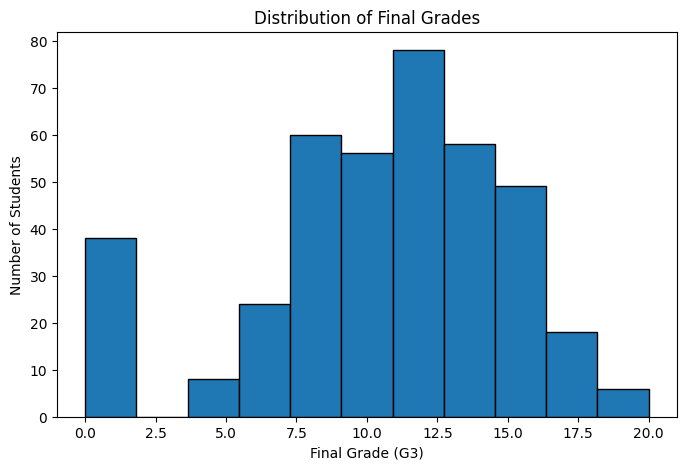

In [ ]:
plt.figure(figsize=(8,5))
plt.hist(df["G3"], bins=11, edgecolor="black")
plt.xlabel("Final Grade (G3)")
plt.ylabel("Number of Students")
plt.title("Distribution of Final Grades")
plt.show()

## Study time vs final grade

In [ ]:


studytime_performance = df.groupby("studytime")["G3"].agg(
    ["count", "mean", "median", "min", "max"]
).round(2)

print("Final Grade by Study Time:")
display(studytime_performance)



Final Grade by Study Time:


,count,mean,median,min,max
studytime,,,,,
1,105,10.05,10.0,0,19
2,198,10.17,11.0,0,19
3,65,11.40,12.0,0,19
4,27,11.26,12.0,0,20


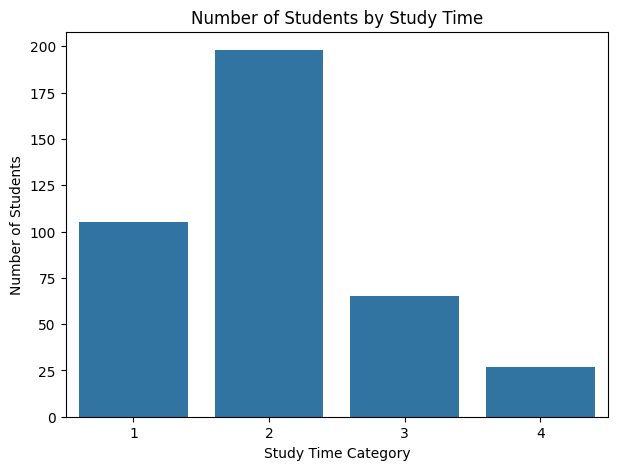

In [ ]:
plt.figure(figsize=(7,5))
sns.countplot(data=df, x="studytime")
plt.xlabel("Study Time Category")
plt.ylabel("Number of Students")
plt.title("Number of Students by Study Time")
plt.show()

<Figure size 800x500 with 0 Axes>

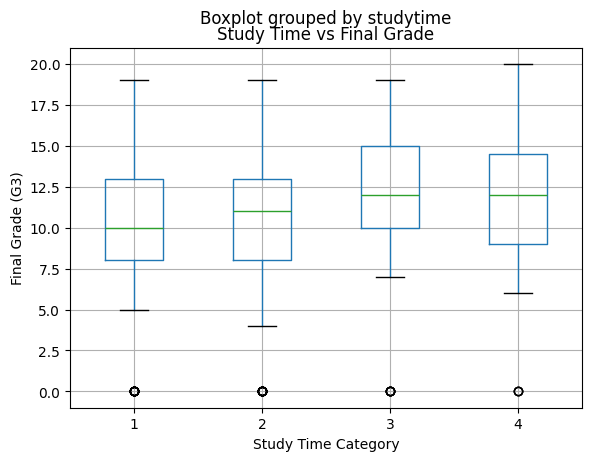

In [ ]:
plt.figure(figsize=(8,5))
df.boxplot(column="G3", by="studytime")
plt.xlabel("Study Time Category")
plt.ylabel("Final Grade (G3)")
plt.title("Study Time vs Final Grade")
plt.show()

## Attendance related to Grades

In [ ]:
print("Correlation between absences and final grade:")
print(df["absences"].corr(df["G3"]))


Correlation between absences and final grade:
0.03424731615006931


In [ ]:
absence_grade = df.groupby("absences")["G3"].mean()
print(absence_grade.head(20))

absences
0      8.443478
1     13.000000
2     11.907692
3     11.500000
4     11.283019
5     11.600000
6     11.774194
7     11.857143
8     10.590909
9     13.333333
10    11.235294
11    11.666667
12    10.750000
13    12.666667
14     9.333333
15     8.333333
16     9.857143
17    10.000000
18     8.400000
19    10.000000
Name: G3, dtype: float64


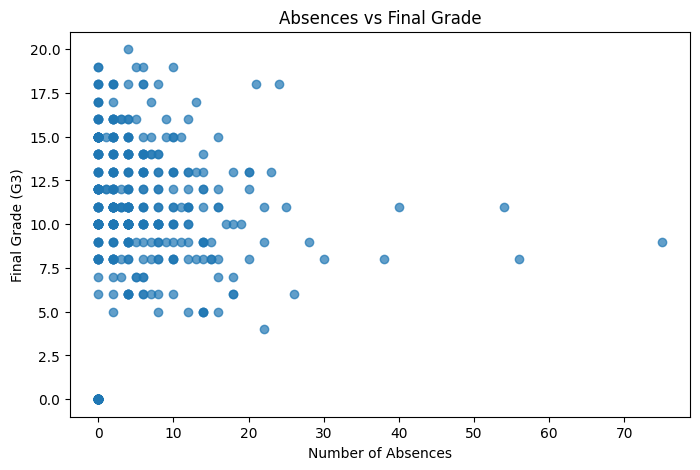

In [ ]:
plt.figure(figsize=(8,5))
plt.scatter(df["absences"], df["G3"], alpha=0.7)
plt.xlabel("Number of Absences")
plt.ylabel("Final Grade (G3)")
plt.title("Absences vs Final Grade")
plt.show()

## Parental education vs final grade

In [ ]:
mother_education = df.groupby("Medu")["G3"].agg(
    ["count", "mean", "median"]
).round(2)
print("Mother's Education:")
display(mother_education)


Mother's Education:


,count,mean,median
Medu,,,
0,3,13.00,15.0
1,59,8.68,10.0
2,103,9.73,11.0
3,99,10.30,10.0
4,131,11.76,12.0


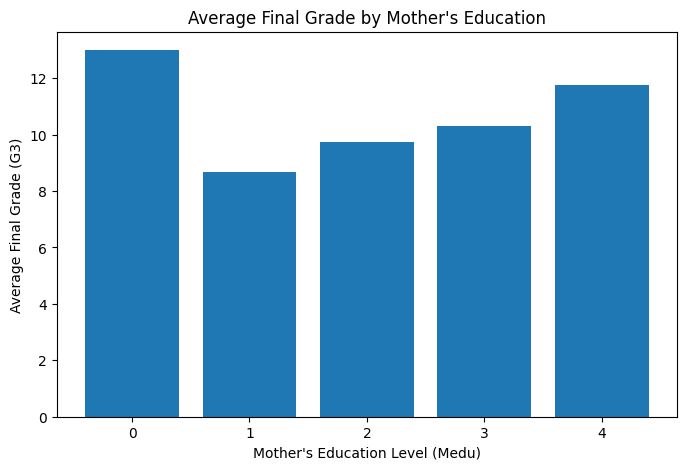

In [ ]:
mother_edu_mean = df.groupby("Medu")["G3"].mean()

plt.figure(figsize=(8,5))
plt.bar(mother_edu_mean.index.astype(str), mother_edu_mean.values)
plt.xlabel("Mother's Education Level (Medu)")
plt.ylabel("Average Final Grade (G3)")
plt.title("Average Final Grade by Mother's Education")
plt.show()

In [ ]:
father_education = df.groupby("Fedu")["G3"].agg(
    ["count", "mean", "median"]
).round(2)
print("Father's Education:")
display(father_education)

Father's Education:


,count,mean,median
Fedu,,,
0,2,13.00,13.0
1,82,9.16,10.0
2,115,10.26,11.0
3,100,10.66,10.0
4,96,11.36,12.0


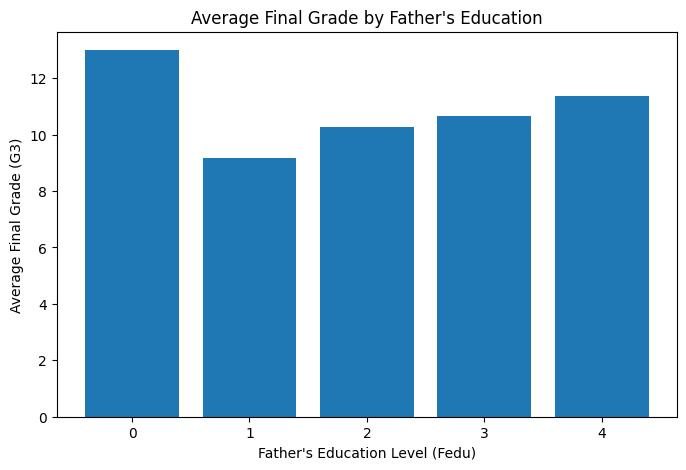

In [ ]:
father_edu_mean = df.groupby("Fedu")["G3"].mean()

plt.figure(figsize=(8,5))
plt.bar(father_edu_mean.index.astype(str), father_edu_mean.values)
plt.xlabel("Father's Education Level (Fedu)")
plt.ylabel("Average Final Grade (G3)")
plt.title("Average Final Grade by Father's Education")
plt.show()

## Family background vs outcomes

In [ ]:
print("Average grade by family size:")
display(
    df.groupby("famsize")["G3"]
    .agg(["count", "mean", "median"])
    .round(2)
)

Average grade by family size:


,count,mean,median
famsize,,,
GT3,281,10.18,11.0
LE3,114,11.00,11.0


In [ ]:
print("Average grade by parents' status:")
display(
    df.groupby("Pstatus")["G3"]
    .agg(["count", "mean", "median"])
    .round(2)
)


Average grade by parents' status:


,count,mean,median
Pstatus,,,
A,41,11.20,11.0
T,354,10.32,11.0


In [ ]:

print("Average grade by family relationship quality:")
display(
    df.groupby("famrel")["G3"]
    .agg(["count", "mean", "median"])
    .round(2)
)

Average grade by family relationship quality:


,count,mean,median
famrel,,,
1,8,10.62,12.0
2,18,9.89,11.0
3,68,10.04,10.5
4,195,10.36,11.0
5,106,10.83,11.0


In [ ]:
print("Average grade by guardian:")
display(
    df.groupby("guardian")["G3"]
    .agg(["count", "mean", "median"])
    .round(2)
)

Average grade by guardian:


,count,mean,median
guardian,,,
father,90,10.69,11.0
mother,273,10.48,11.0
other,32,9.06,9.5


**Previous academic performance vs final grade** Both scatter plot an d bar graph visualisation given below

In [ ]:
print("Correlation of previous grades with final grade:")

print("G1 vs G3:", round(df["G1"].corr(df["G3"]), 3))
print("G2 vs G3:", round(df["G2"].corr(df["G3"]), 3))

Correlation of previous grades with final grade:
G1 vs G3: 0.801
G2 vs G3: 0.905


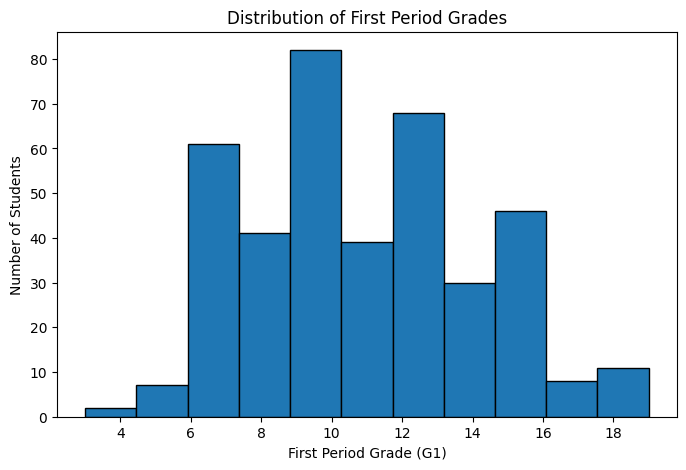

In [ ]:
plt.figure(figsize=(8,5))

plt.hist(df["G1"], bins=11, edgecolor="black")
plt.xlabel("First Period Grade (G1)")
plt.ylabel("Number of Students")
plt.title("Distribution of First Period Grades")
plt.show()

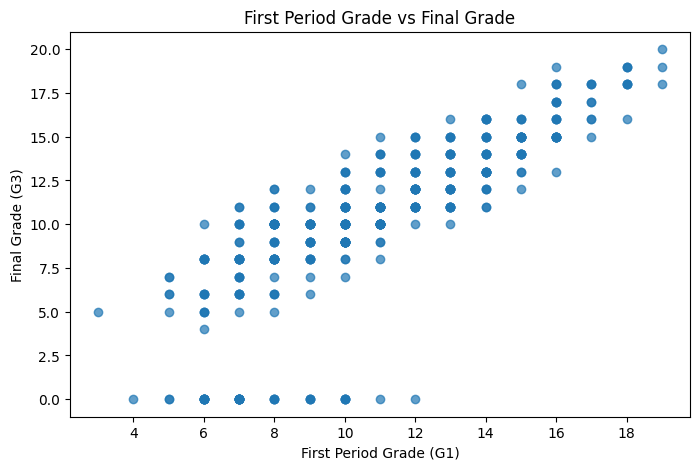

In [ ]:
plt.figure(figsize=(8,5))
plt.scatter(df["G1"], df["G3"], alpha=0.7)
plt.xlabel("First Period Grade (G1)")
plt.ylabel("Final Grade (G3)")
plt.title("First Period Grade vs Final Grade")
plt.show()

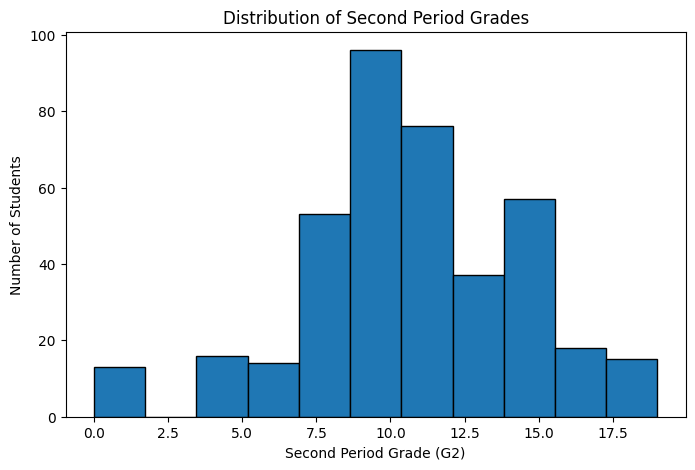

In [ ]:
plt.figure(figsize=(8,5))

plt.hist(df["G2"], bins=11, edgecolor="black")
plt.xlabel("Second Period Grade (G2)")
plt.ylabel("Number of Students")
plt.title("Distribution of Second Period Grades")
plt.show()

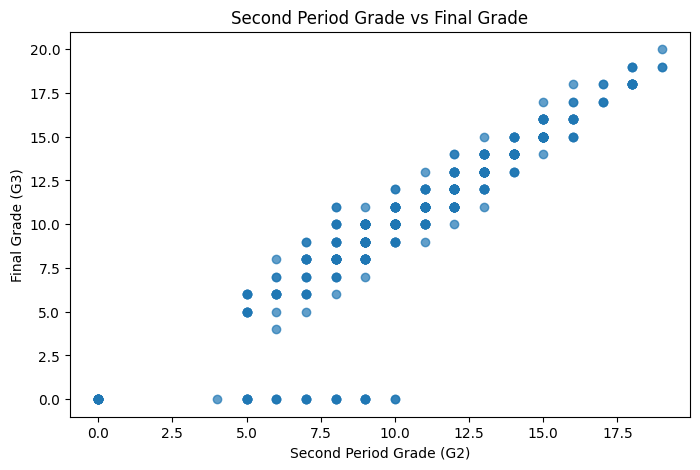

In [ ]:
plt.figure(figsize=(8,5))

plt.scatter(df["G2"], df["G3"], alpha=0.7)
plt.xlabel("Second Period Grade (G2)")
plt.ylabel("Final Grade (G3)")
plt.title("Second Period Grade vs Final Grade")
plt.show()

## Extracurricular activities vs final grade
 **in both boxplot and bar graph**

In [ ]:


activities_performance = df.groupby("activities")["G3"].agg(
    ["count", "mean", "median", "min", "max"]
).round(2)

print(activities_performance)

            count   mean  median  min  max
activities                                
no            194  10.34    11.0    0   19
yes           201  10.49    11.0    0   20


<Figure size 700x500 with 0 Axes>

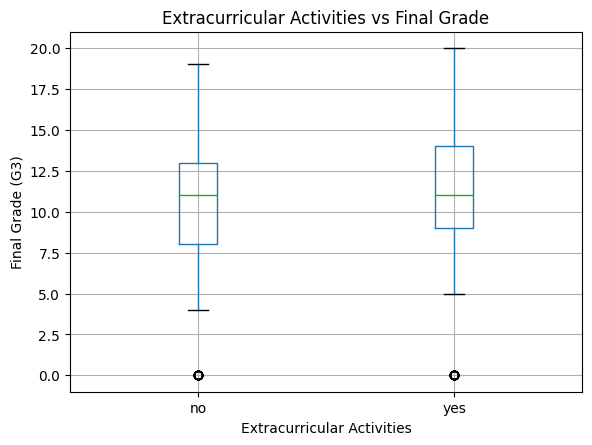

In [ ]:
plt.figure(figsize=(7,5))

df.boxplot(column="G3", by="activities")
plt.xlabel("Extracurricular Activities")
plt.ylabel("Final Grade (G3)")
plt.title("Extracurricular Activities vs Final Grade")
plt.suptitle("")
plt.show()

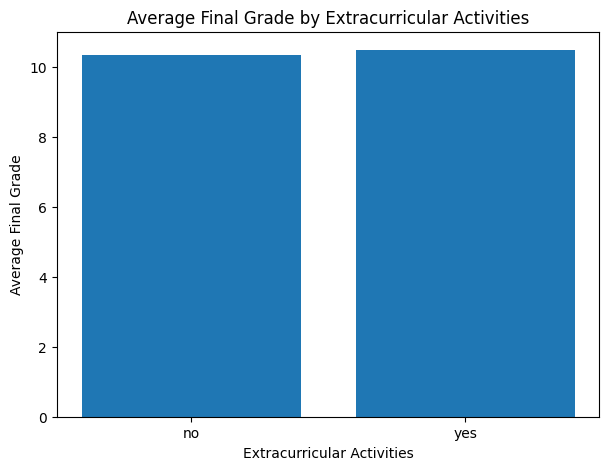

In [ ]:
plt.figure(figsize=(7,5))

activity_mean = df.groupby("activities")["G3"].mean()

plt.bar(activity_mean.index, activity_mean.values)
plt.xlabel("Extracurricular Activities")
plt.ylabel("Average Final Grade")
plt.title("Average Final Grade by Extracurricular Activities")
plt.show()

## Performance by sex

In [ ]:
print("Number of students by sex:")
display(df["sex"].value_counts())

Number of students by sex:


,count
sex,
F,208
M,187


In [ ]:
sex_performance = df.groupby("sex")["G3"].agg(
    ["count", "mean", "median", "min", "max"]
).round(2)

display(sex_performance)

,count,mean,median,min,max
sex,,,,,
F,208,9.97,10.0,0,19
M,187,10.91,11.0,0,20


<Figure size 700x500 with 0 Axes>

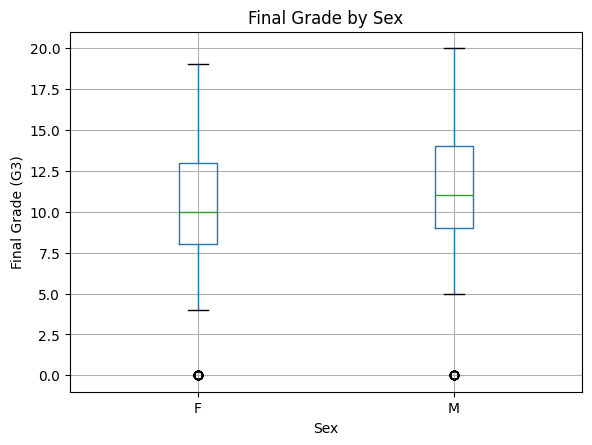

In [ ]:
plt.figure(figsize=(7,5))

df.boxplot(column="G3", by="sex")
plt.xlabel("Sex")
plt.ylabel("Final Grade (G3)")
plt.title("Final Grade by Sex")
plt.suptitle("")
plt.show()

**Also can be visualised by countplot**

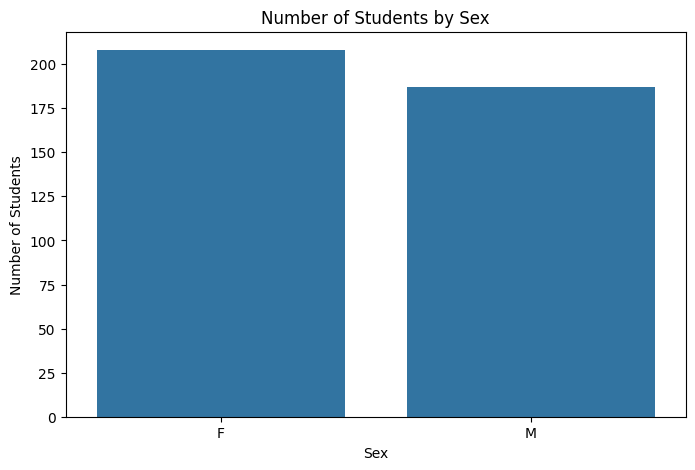

In [ ]:
plt.figure(figsize=(8,5))
sns.countplot(data=df, x="sex")
plt.xlabel("Sex")
plt.ylabel("Number of Students")
plt.title("Number of Students by Sex")
plt.show()

## Correlation of numerical variables with final grade

In [ ]:
num_df = df.select_dtypes(include="number")

correlation_with_g3 = num_df.corr()["G3"].sort_values(ascending=False)

print("Correlation of numerical variables with final grade:")
display(correlation_with_g3)

Correlation of numerical variables with final grade:


,G3
G3,1.000000
G2,0.904868
G1,0.801468
Medu,0.217147
Fedu,0.152457
studytime,0.097820
famrel,0.051363
absences,0.034247
freetime,0.011307
Walc,-0.051939


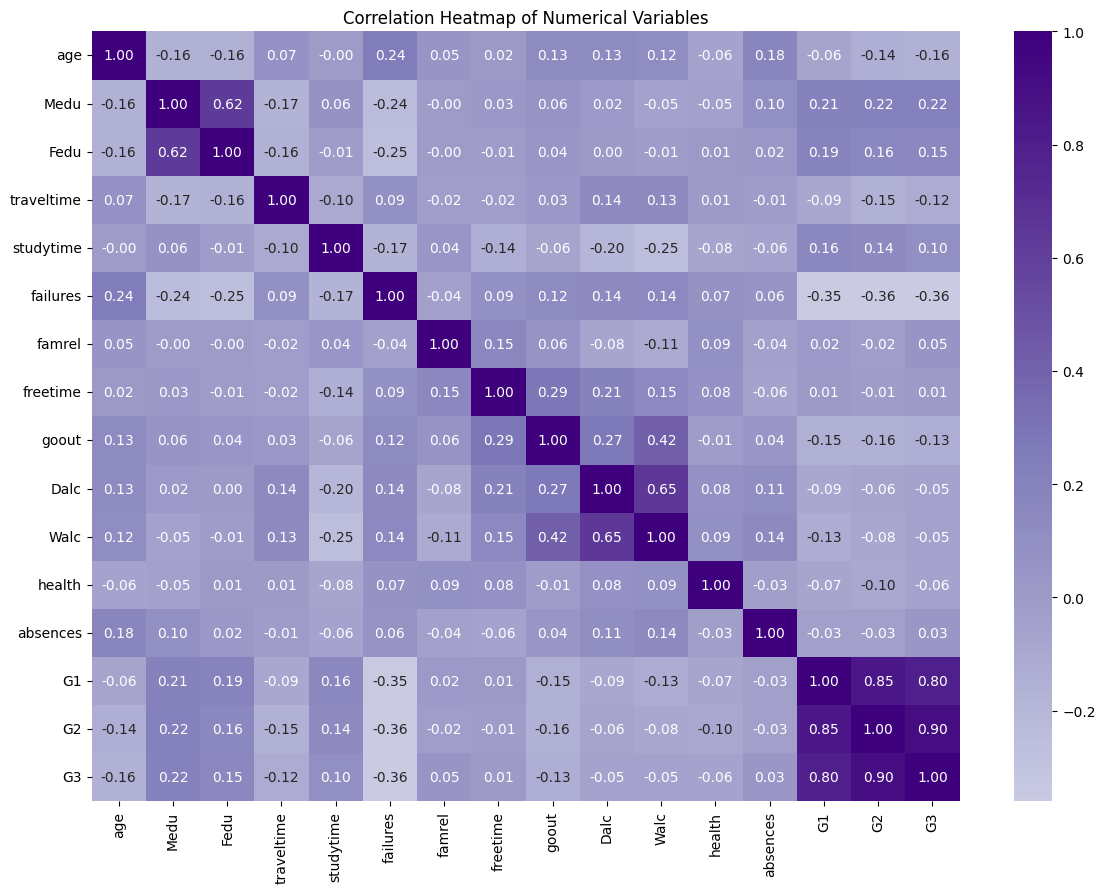

In [ ]:
plt.figure(figsize=(14,10))

correlation_matrix = num_df.corr()

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="Purples",
    center=0
)

plt.title("Correlation Heatmap of Numerical Variables")
plt.show()

## Unusually high or low performance

In [ ]:
Q1 = df["G3"].quantile(0.25)
Q3 = df["G3"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

performance_outliers = df[
    (df["G3"] < lower_bound) |
    (df["G3"] > upper_bound)
]

print("Number of unusual performance records:", len(performance_outliers))

display(performance_outliers[["sex", "age", "studytime", "failures","absences", "G1", "G2", "G3"]])

Q1: 8.0
Q3: 14.0
IQR: 6.0
Lower Bound: -1.0
Upper Bound: 23.0
Number of unusual performance records: 0


,sex,age,studytime,failures,absences,G1,G2,G3


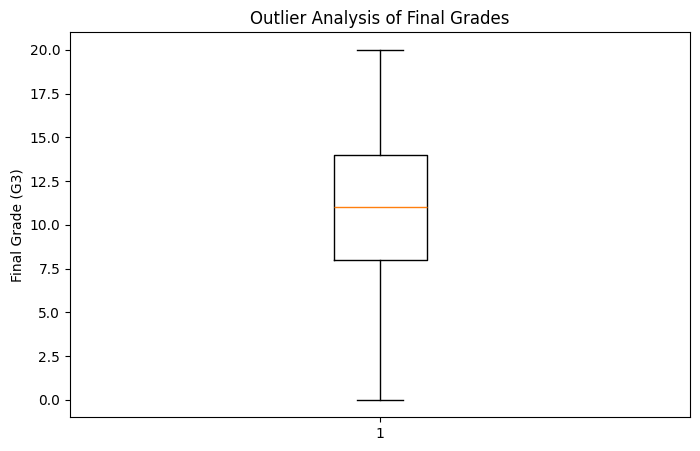

In [ ]:
plt.figure(figsize=(8,5))

plt.boxplot(df["G3"])
plt.ylabel("Final Grade (G3)")
plt.title("Outlier Analysis of Final Grades")
plt.show()


## Insights
- The final grade (G3) shows that students have different levels of academic performance, with many students having grades around the middle range.
- Study time shows some differences in final grades. Students in different study-time categories have different G3 values.
- The relationship between absences and final grades is very weak. The correlation between absences and G3 is almost non linear relationship here. the student who are not absent can also have weak grades
- The education levels of both mothers and fathers show some differences in the average final grades of students.
- Family-related factors such as family size, parents' living status, family relationship quality, and guardian also show some differences in student performance.
- Previous academic performance has a strong relationship with the final grade. The correlation between G1 and G3 is about 0.801, while the correlation between G2 and G3 is about 0.905.
- Students who participate in extracurricular activities have an average final grade of about 10.49, while students who do not participate have an average of about 10.34. The difference is small.
- There are some differences in the average final grades of male (10.91) and female students(9.97).
- Among the numerical variables analyzed, G1 and G2 have the strongest relationships with the final grade G3 (very closed to eachother).
- The outlier analysis found some students with unusually high or low final grades.



## Recommendations

- Monitor previous academic performance because G1 and especially G2 have strong relationships with final grade G3.
- Encourage effective study habits because differences across study-time categories suggest a relationship with academic performance.
- Monitor attendance as part of overall student engagement, while recognizing that absences showed only a very weak linear relationship with G3 in this dataset.
- Provide additional academic support to students showing repeated failures or consistently low previous grades.
- Consider family and parental factors as contextual information when understanding student performance, rather than treating them as direct causes.
- Support extracurricular participation appropriately because the difference in average grades between students with and without activities is small.
- Investigate unusual performance records individually to determine whether they represent genuine exceptional performance or unusual circumstances.

## Limitations
- The analysis uses the **student-mat.csv** dataset, which focuses on mathematics performance, so the results may not apply to other subjects.
- The dataset contains 395 students, so the findings are limited to the students included in this dataset.
- The dataset is observational, so it cannot be used to prove cause-and-effect relationships.
- Some variables describe student and family conditions and may not represent every detail of those situations.
- The dataset contains the number of absences, but it does not provide a complete attendance measure. Therefore, attendance was analyzed using absences.
- Outliers were identified during the analysis but were not automatically removed because an unusual value may still be a genuine student result.
- There may be other factors affecting academic performance that are not included in this dataset.


## Conclusion

This EDA helped identify the main factors related to students' final grades. Previous grades, especially G1 and G2, showed the strongest relationship with G3. Study time, family factors, and parental education also showed some differences, while absences had a very weak relationship with final grades. Overall, previous academic performance was the strongest factor found in this analysis.

